# 0050：融資維持率跌破門檻後長期持有
## tl;dr
**這是 2021-11-03～2026-10-14 的初步回測，不是原規劃的 2010 年起完整長期驗證。**
每月投入資金 1 萬元、訊號買進 10 萬元、持有不賣。在相同累計入金 60 萬元下，定期定額期末資產約 180.21 萬元；140%／150%／160% 門檻約為 117.80／148.61／157.87 萬元，均含閒置現金。130% 沒有訊號。

本期間低水位買入的已投資部分表現良好，但等待與資金不足令整體績效落後定期定額。這不能證明所有時期都如此，也不能用四個門檻挑出具有統計把握的最佳水位。

## Context & Methods
使用者選擇 0050、每次由上往下跌破水位固定金額買入、長期不賣出；資金按月新增，累積現金等待訊號。

### Key Assumptions
- 每月第一個樣本內交易日入金 10,000 元，起始現金為零；首筆為 2021-11-03，共 60 筆。
- 比較門檻 130%、140%、150%、160%。前一交易日大於等於門檻、當日嚴格低於門檻才觸發；連續低於不重複買。
- 訊號盤後才能得知，因此下一可交易日開盤買入。現金至少 100,000 元才買，包含買入手續費；不足即跳過、不排隊補買、不借款。
- 買入手續費假設為 0.1425%，無最低費用；用可分割等值單位模擬，不處理整股／零股價差、滑價與成交量限制。
- 使用含配息及分割調整價格，等同稅前股息立即再投入的理論總報酬；不是股息實際發放日、逐股整數再投資的現金簿模擬。未計個人股息稅。
- 2025-06-11～06-17 分割停牌期間不允許成交。2025 年 1 拆 4 已反映於本區間調整價格，不再重複除以四或增加等值單位。
- 現金基準利率 0%，另試 2%；回測期末按市值估價，不假設賣出，故無期末賣出費用。
- XIRR 以每月實際入金及期末股票加現金計算。最大回撤以扣除入金影響的每日組合淨值近似計算，包含現金。
- 單筆訊號前瞻報酬可重疊，尤其 2022 年多筆屬同一次熊市，不是獨立事件。
- 本分析是同一歷史樣本的探索比較，沒有獨立樣本外驗證。

## Data
### 來源與限制
1. [愛玩股上市融資維持率歷史](https://www.istock.tw/post/twmarginrequirement_more)：透過公開網頁第 1～20 頁讀取共 1,200 個交易日，2021-11-03～2026-10-14、無重複日期、最低 130.30%。採上市口徑、分子分母含 ETF，頁面說明無收盤價者沿用前價。資料四捨五入至小數兩位，可能影響接近門檻的分類。
   - 從完整序列擷取 44 個跨越事件，保留前日數值、訊號日及下一交易日於 `signals.csv`。130% 零筆、140% 六筆、150% 十一筆、160% 二十七筆。
   - `signals.csv` 是固定四個門檻的事件資料，不是完整維持率日序列；因此不可直接用它回測其他門檻。完整日資料此次未另存檔，原始查詢可由上方來源分頁回查。
2. [Yahoo Finance 0050 歷史行情](https://finance.yahoo.com/quote/0050.TW/history/)：`raw/0050-yahoo2.json` 保存開盤、收盤、調整收盤、股息事件。只有 2021 年後的已檢查區間用於回測；較早資料有 2013／2014 價格尺度不一致，沒有拿來計算。
3. [證交所 2026-10-14 每日行情](https://www.twse.com.tw/exchangeReport/MI_INDEX?response=json&date=20261014&type=ALLBUT0999)：補 Yahoo 當日缺價，0050 開盤、收盤均 113 元；相鄰 10/12、10/13 的開收盤與官方一致。近期調整因子為 1。
4. [元大 0050 分割說明](https://www.yuantafunds.com/active/ETF0050/index.html)：2025 年 1 拆 4，6/18 恢復交易。行情中停牌日成交量為零並排除成交。

原規劃從證交所逐日重建 2010 年起訊號，但官方批次存取遭安全限制，已停止請求。`raw/twse` 只是部分早期快取，**未用於本次五年訊號計算**。本週 10/12、10/13、10/14 的第三方維持率與先前官方逐股試算均一致至小數兩位；此抽查不是全歷史逐日驗證。

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image
import run_backtest as bt
ROOT=Path.cwd()
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    prices, signals, summary=bt.main()
daily=pd.read_csv(ROOT/'daily_portfolios.csv',parse_dates=['date'])
trades=pd.read_csv(ROOT/'trades.csv',parse_dates=['date'])
sensitivity=pd.read_csv(ROOT/'sensitivity.csv')
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2,'figure.dpi':130})
colors={'DCA':'#222222','Below 130%':'#9a9a9a','Below 140%':'#cd8b23','Below 150%':'#4e708e','Below 160%':'#5b7350'}
assert summary.total_contributions.nunique()==1
assert summary.total_contributions.iloc[0]==600000
assert len(prices)==1200
summary[['strategy','signals','buys','skipped_cash','ending_nav','ending_cash','portfolio_xirr_pct','flow_adjusted_mdd_pct']].round(2)

,strategy,signals,buys,skipped_cash,ending_nav,ending_cash,portfolio_xirr_pct,flow_adjusted_mdd_pct
0,DCA,60,60,0,1802143.37,0.0,46.55,-33.77
1,Below 130%,0,0,0,600000.00,600000.0,0.00,0.00
2,Below 140%,6,2,4,1178016.63,400000.0,27.87,-11.51
3,Below 150%,11,4,7,1486088.72,200000.0,37.95,-19.90
4,Below 160%,27,5,22,1578701.50,100000.0,40.62,-26.34


## Results
### 相同入金下的總資產
下圖包含等待訊號的現金，因此可以和每月定期定額比較。期末並未賣出。

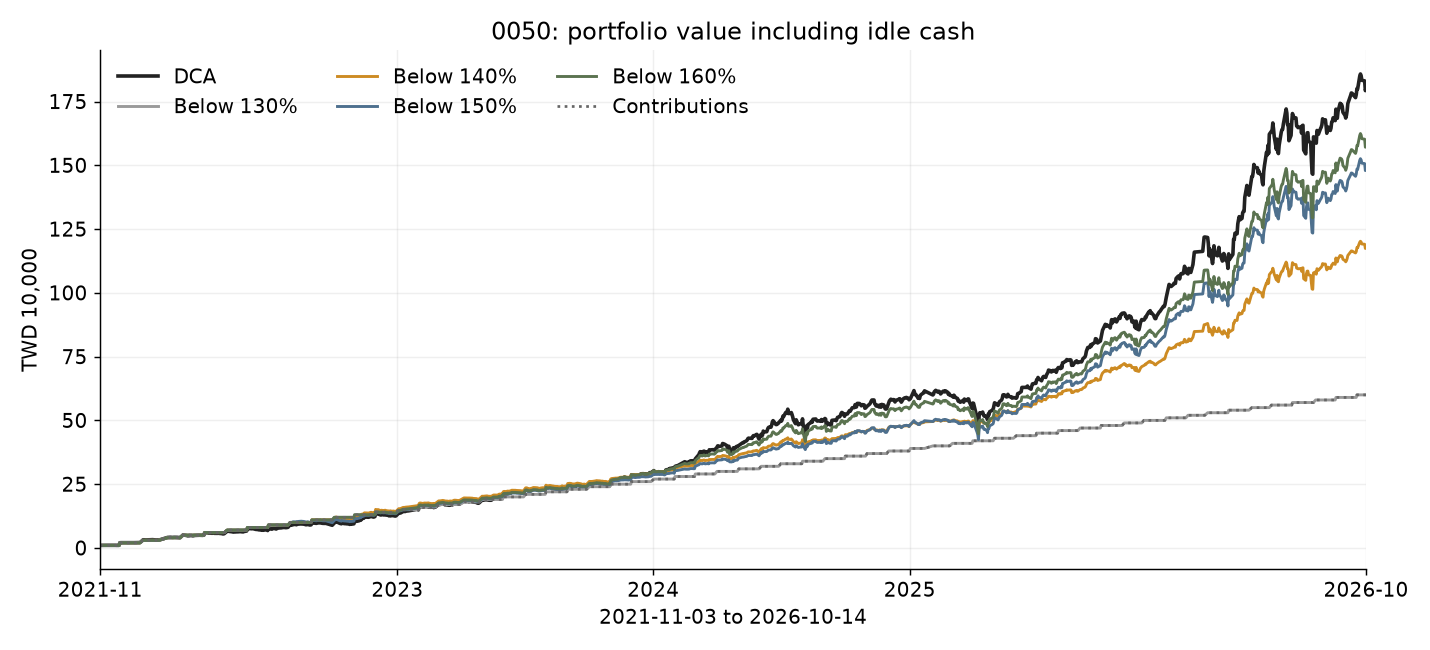

In [2]:
fig,ax=plt.subplots(figsize=(11,5))
for name,g in daily.groupby('strategy',sort=False):
    ax.plot(g.date,g.nav/10000,label=name,color=colors[name],lw=2 if name=='DCA' else 1.6)
g=daily[daily.strategy=='DCA']
ax.plot(g.date,g.contributed/10000,label='Contributions',color='#666666',ls=':',lw=1.5)
ax.set(title='0050: portfolio value including idle cash',ylabel='TWD 10,000',xlabel='2021-11-03 to 2026-10-14')
ax.set_xlim(bt.START,bt.END)
ax.set_xticks(pd.to_datetime(['2021-11-03','2023-01-01','2024-01-01','2025-01-01','2026-10-14']),['2021-11','2023','2024','2025','2026-10'])
ax.legend(ncol=3,frameon=False,loc='upper left')
fig.tight_layout();fig.savefig(ROOT/'portfolio_comparison.png');display(Image(filename=str(ROOT/'portfolio_comparison.png')));plt.close(fig)

### 較低回撤的代價
門檻策略持有更多現金，較小回撤並不等於訊號本身提供超額報酬。只算已投入部位的 XIRR 會忽略等待期間的現金，不能拿來代替整體策略報酬。

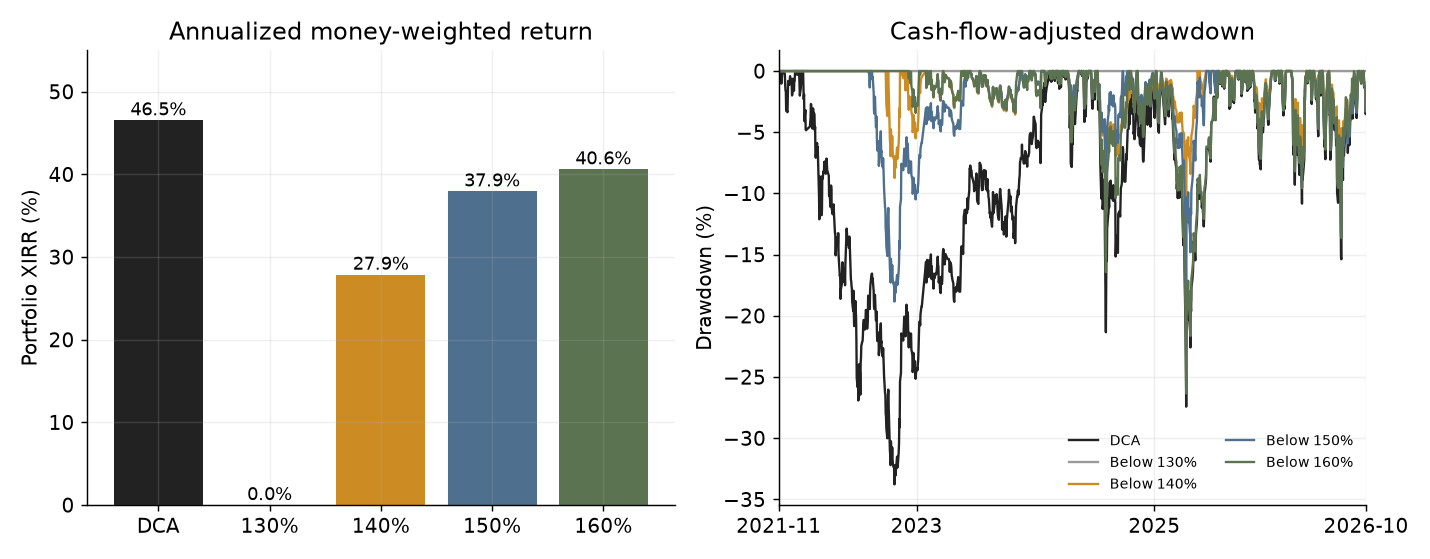

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
labels=['DCA','130%','140%','150%','160%']
axes[0].bar(labels,summary.portfolio_xirr_pct,color=[colors[x] for x in summary.strategy])
axes[0].set(title='Annualized money-weighted return',ylabel='Portfolio XIRR (%)')
for i,v in enumerate(summary.portfolio_xirr_pct):axes[0].text(i,v+.6,f'{v:.1f}%',ha='center',fontsize=10)
axes[0].set_ylim(0,55)
for name,g in daily.groupby('strategy',sort=False):
    dd=(g.twr_index/g.twr_index.cummax()-1)*100
    axes[1].plot(g.date,dd,label=name,color=colors[name],lw=1.3)
axes[1].set(title='Cash-flow-adjusted drawdown',ylabel='Drawdown (%)')
axes[1].set_xlim(bt.START,bt.END)
axes[1].set_xticks(pd.to_datetime(['2021-11-03','2023-01-01','2025-01-01','2026-10-14']),['2021-11','2023','2025','2026-10'])
axes[1].legend(fontsize=8,frameon=False,ncol=2)
fig.tight_layout();fig.savefig(ROOT/'return_and_drawdown.png');display(Image(filename=str(ROOT/'return_and_drawdown.png')));plt.close(fig)

### 實際買入紀錄
現金不足時跳過訊號，所以實際買入次數少於觸發次數。

In [4]:
trades.loc[trades.strategy!='DCA',['strategy','date','signal_date','signal_ratio','amount_including_fee']].reset_index(drop=True)

,strategy,date,signal_date,signal_ratio,amount_including_fee
0,Below 140%,2022-09-29,2022-09-28,136.37,100000.0
1,Below 140%,2025-04-08,2025-04-07,139.68,100000.0
2,Below 150%,2022-08-04,2022-08-03,148.96,100000.0
3,Below 150%,2024-08-06,2024-08-05,148.20,100000.0
4,Below 150%,2025-04-01,2025-03-31,147.42,100000.0
5,Below 150%,2025-04-08,2025-04-07,139.68,100000.0
6,Below 160%,2022-12-08,2022-12-07,158.61,100000.0
7,Below 160%,2023-11-01,2023-10-31,157.50,100000.0
8,Below 160%,2024-08-05,2024-08-02,159.51,100000.0
9,Below 160%,2025-02-04,2025-02-03,158.70,100000.0


### 買入金額與現金利率敏感度
這些是事先列出的替代假設，不是調參後宣稱的最佳策略。每月入金維持 1 萬元不變。

In [5]:
sensitivity[['strategy','ticket','cash_rate','buys','ending_nav','portfolio_xirr_pct']].round(2)

,strategy,ticket,cash_rate,buys,ending_nav,portfolio_xirr_pct
0,Below 130%,10000.0,0.00,0,600000.00,0.00
1,Below 140%,10000.0,0.00,6,814606.28,12.41
2,Below 150%,10000.0,0.00,11,909464.25,16.97
3,Below 160%,10000.0,0.00,26,1183779.50,28.08
4,Below 130%,50000.0,0.00,0,600000.00,0.00
5,Below 140%,50000.0,0.00,3,1068508.54,23.72
6,Below 150%,50000.0,0.00,6,1299328.77,32.09
7,Below 160%,50000.0,0.00,9,1566571.70,40.28
8,Below 130%,100000.0,0.00,0,600000.00,0.00
9,Below 140%,100000.0,0.00,2,1178016.63,27.87


### 單筆訊號後報酬
這裡每個事件都計算，包括當時現金不足未執行的訊號。只取持有期限已完整走完的樣本；不將尚未滿三年、五年的事件填成零。

In [6]:
events=pd.read_csv(ROOT/'signal_forward_returns.csv')
events.groupby('threshold').agg(signals=('signal_date','count'),one_year_samples=('return_1y_pct','count'),mean_one_year_pct=('return_1y_pct','mean'),three_year_samples=('return_3y_pct','count'),mean_three_year_pct=('return_3y_pct','mean'),five_year_samples=('return_5y_pct','count')).round(2)

,signals,one_year_samples,mean_one_year_pct,three_year_samples,mean_three_year_pct,five_year_samples
threshold,,,,,,
140,6,6,40.53,5,150.25,0
150,11,11,38.36,7,93.59,0
160,27,26,29.76,13,76.42,0


## Takeaways
- 在這段樣本與指定入金方式下，單純等待低維持率買入的總資產落後定期定額。130% 太低，沒有交易；140% 真正執行只有兩筆。
- 降低門檻不一定提高整體報酬：訊號變少會增加等待成本；買入金額也決定現金能否在危機期間部署。
- 未投入現金給予 2% 年利率後，此次比較的排序不變。
- 本段不足五年，沒有任何完整五年持有的訊號樣本；長期策略仍需更早連續資料及未參與選參的樣本外期間。
- 此結果只適用本次含 ETF 的上市維持率口徑，不能直接移用至分子排 ETF、分母含 ETF 的混合指標。

### 重跑
在本資料夾安裝 `numpy pandas scipy matplotlib nbformat nbclient ipykernel`，先執行 `python run_backtest.py` 更新結果，再從上到下執行本 Notebook。`signals.csv` 可逐筆稽核；改門檻須先取得完整日序列，不能只修改參數。